**Load the Dataset**

The dataset is loaded into a Pandas DataFrame for analysis. The first few rows are displayed to understand the available columns and the structure of the data.

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
print(df)



**Dataset Inspection**

The dataset is inspected to understand the number of rows and columns, column names, data types, and sample records. This step helps identify the information available for further analysis.

In [9]:
print("\nFirst five rows:\n ",df.head())
print("\n column names :")
print(df.shape, df.columns.tolist())
print("/n Dataset Information")
print(df.info)


First five rows:
     sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5) ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
<bound method DataFrame.info of      sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ..

**Summary Statistics**

Summary statistics help us understand the central tendency, spread, and range of numerical variables such as sales, profit, quantity, and discount.

In [10]:
print("\n summary Statstics")
print(df.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


**Data Cleaning and Preprocessing**

Data cleaning is performed to identify missing values, remove duplicate records, and verify the data types. This ensures that the dataset is suitable for further analysis.

In [11]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Check data types
print("\nData types:")
print(df.dtypes)

print("\nDataset shape after removing duplicates:", df.shape)

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of duplicate rows: 1

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

Dataset shape after removing duplicates: (149, 5)


Observation – Data Cleaning

The Iris dataset initially contained 150 rows and 5 columns. No missing values were found in any column. One duplicate row was identified and removed using the "drop_duplicates()" method. After removing the duplicate, the dataset contained 149 rows and 5 columns. The dataset is now ready for further exploratory data analysis.

**Missing Values Analysis**

A heatmap is used to visualize missing values in the Iris dataset. This helps determine whether any columns require additional data cleaning.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
# Check missing values
missing = df.isnull().sum()

if missing.sum() == 0:
    print("No missing values found in the Iris dataset.")
else:
    plt.figure(figsize=(8, 4))
    sns.heatmap(
        df.isnull(),
        cbar=False,
        yticklabels=False,
        cmap="viridis"
    )
    plt.title("Missing Values in Iris Dataset")
    plt.xlabel("Columns")
    plt.show()

No missing values found in the Iris dataset.


**Correlation Analysis**

A correlation heatmap is used to identify relationships between sepal length, sepal width, petal length, and petal width. This helps understand which flower measurements are strongly related.

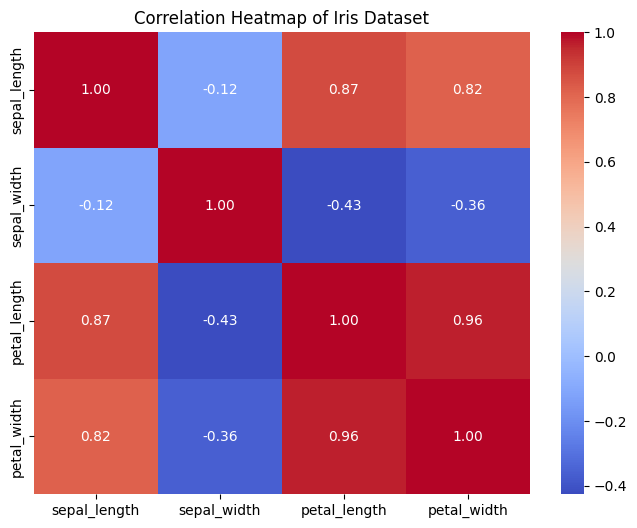

In [18]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Iris Dataset")
plt.show()

Observation – Correlation Heatmap

1. Petal Length and Petal Width: They have a very strong positive correlation of 0.96. This means flowers with longer petals generally tend to have wider petals.

2. Sepal Length and Petal Length: They have a strong positive correlation of 0.87.

3. Sepal Length and Petal Width: They have a strong positive correlation of 0.82.

4. Sepal Width and Petal Length: They have a moderate negative correlation of -0.43.

5. Sepal Width and Petal Width: They have a negative correlation of -0.36.

Conclusion: Petal length and petal width have the strongest positive correlation among the four numerical features. These relationships can help us understand differences among Iris flower measurements.

Sepal Length Distribution

Question: How are sepal length measurements distributed among Iris flowers?

A histogram is used to visualize the distribution of sepal lengths and identify common measurement ranges.

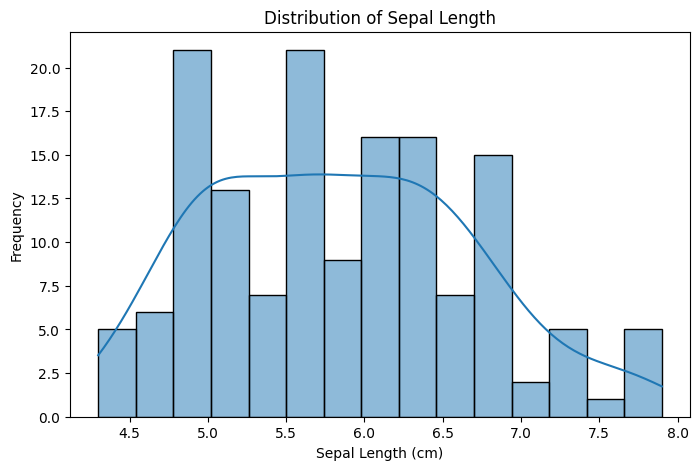

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sepal_length",
    bins=15,
    kde=True
)

plt.title("Distribution of Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")
plt.show()

Outlier Detection

Question: Are there any unusually high or low flower measurements?

Boxplots are used to identify potential outliers in the four numerical features of the Iris dataset.

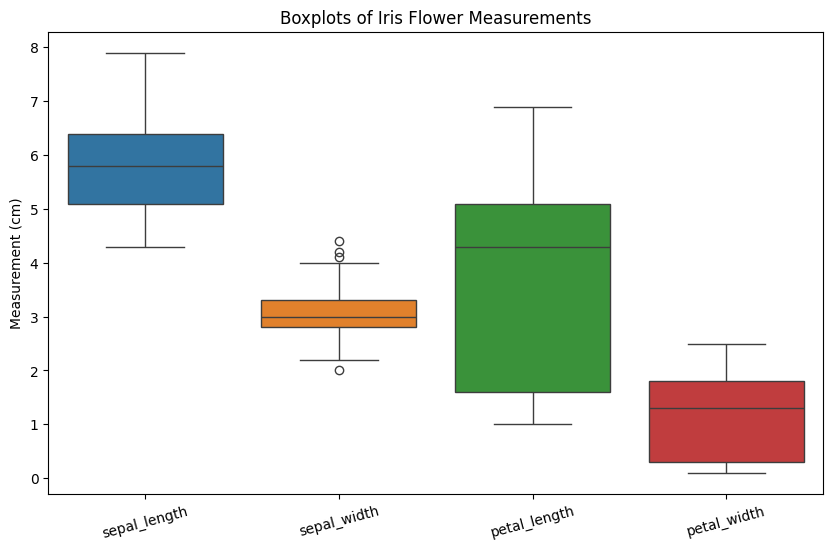

In [20]:
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[features])

plt.title("Boxplots of Iris Flower Measurements")
plt.ylabel("Measurement (cm)")
plt.xticks(rotation=15)
plt.show()

Average Measurements by Species

Question: How do the average flower measurements differ among the three Iris species?

A bar chart compares the average petal length of Setosa, Versicolor, and Virginica.

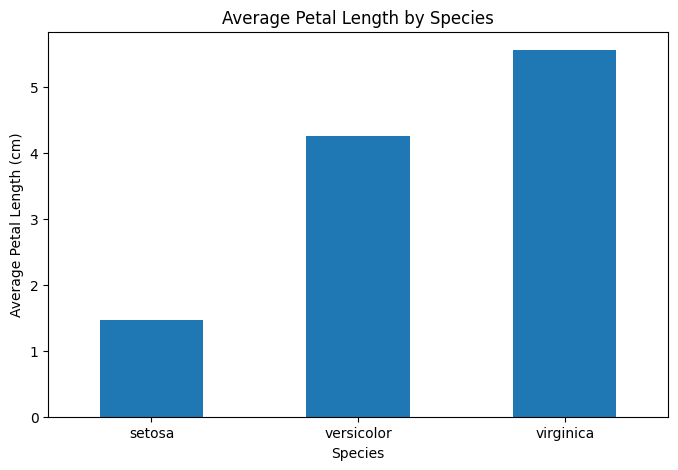

species
setosa        1.462000
versicolor    4.260000
virginica     5.561224
Name: petal_length, dtype: float64


In [21]:
species_petal = df.groupby("species")["petal_length"].mean()

species_petal.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length (cm)")
plt.xticks(rotation=0)
plt.show()

print(species_petal)

Sepal Length vs Sepal Width

Question: Can sepal measurements help distinguish between Iris species?

A scatter plot displays the relationship between sepal length and sepal width, using different colors for each species.

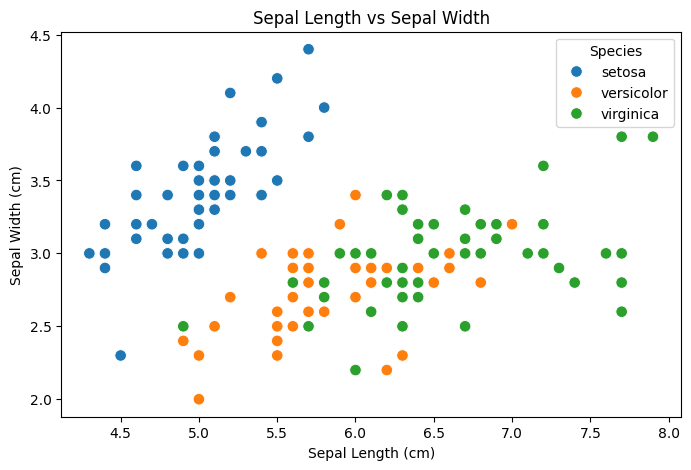

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="sepal_length",
    y="sepal_width",
    hue="species",
    s=70
)

plt.title("Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.legend(title="Species")
plt.show()

Petal Measurements by Species

Question: How do petal length and petal width vary among the three species?

A scatter plot helps visualize the relationship between petal length and petal width and shows how the species form distinct groups.

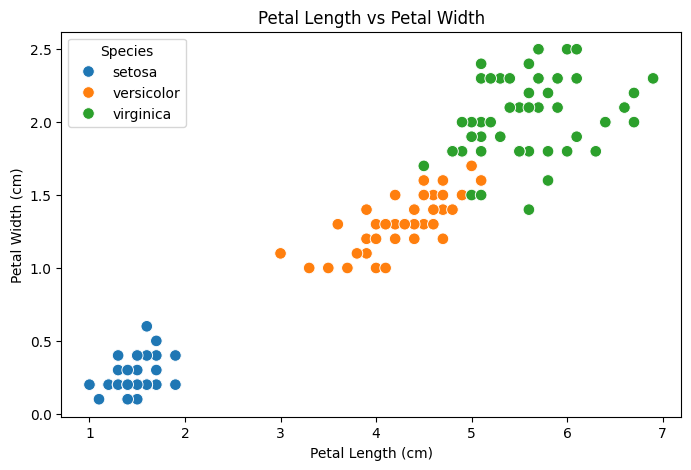

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    s=70
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species")
plt.show()

18. Species Distribution

This visualization shows the number of observations belonging to each Iris species. It helps determine whether the dataset is balanced across the three classes.

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species"
)

plt.title("Number of Samples by Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

print(df["species"].value_counts())

**Top 3 Insights**

1. Petal Measurement Insight: Compare petal length and petal width across species to identify which species has the largest petals.

2. Correlation Insight: Examine the correlation heatmap to identify the strongest positive relationship between numerical features.

3. Species Separation Insight: Observe whether the scatter plot of petal length and petal width shows distinct clusters for the three Iris species.

**Conclusion**

Exploratory Data Analysis was performed on the Iris dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis included data cleaning, missing-value analysis, correlation analysis, summary statistics, and visualizations. These results help us understand the distribution of flower measurements, relationships between features, and differences among the three Iris species.